# 1회차 실습 ② — ‘학습’의 가장 작은 예
## 이진화 임계값 하나를 데이터로 찾기

중간고사에서는 사람이 임계값을 지정하거나 Otsu 알고리즘을 사용했습니다. 이번에는 **사진과 정답을 함께 제공한 뒤, 정답과 가장 잘 맞는 임계값을 컴퓨터가 선택**하게 합니다.

이 노트북은 제공된 Python 예제를 단계별로 나누고, 개념 설명·시각화·추가 실험·해설을 붙인 실습 자료입니다. 실제 도로 사진 대신 정답을 정확히 아는 합성 영상을 사용하므로, 외부 데이터 다운로드 없이 실행할 수 있습니다.

| 구성 요소 | 이번 실습에서의 의미 |
|---|---|
| 입력 데이터 $x$ | 도로 사진의 픽셀 밝기 |
| 정답 $y$ | 사람이 표시했다고 가정한 차선 마스크 |
| 모델 | 밝기가 $T$보다 크면 차선으로 예측하는 규칙 |
| 파라미터 | 임계값 $T$ 하나 |
| 손실 | 도로 영역에서 잘못 분류한 픽셀의 비율 |
| 학습 방법 | $T=0,1,\ldots,255$를 모두 시험하는 완전 탐색 |
| 평가 | 새 사진에 학습한 $T$를 그대로 적용 |

**학습 목표**

1. 입력·정답·예측·파라미터·손실을 구분합니다.
2. 손실 함수와 손실 곡선의 관계를 설명합니다.
3. 학습 오답률과 새 데이터 오답률이 다른 이유를 해석합니다.
4. 조명 변화와 클래스 불균형을 직접 확인합니다.

권장 순서: 위에서부터 실행 → 기본 실습 → 결과 해석 → 추가 실험 → 확인 문제. 예상 실습 시간은 약 40~60분입니다.


## 0. 실행 준비

Jupyter Notebook, JupyterLab 또는 VS Code의 Jupyter 환경에서 **커널을 선택한 뒤 ‘모두 실행’**하세요. 필요한 패키지는 `numpy`, `opencv-python`, `matplotlib`입니다.

설치 오류가 나면 아래 설치 셀의 주석을 해제하고 실행하세요. `%pip`는 현재 노트북 커널의 Python 환경에 설치합니다. 설치 후 필요하면 커널을 재시작합니다. Google Colab에서도 같은 순서로 실행할 수 있습니다.

설명은 한국어로, 그림 제목과 축은 글꼴 설치에 영향을 덜 받도록 영어로 표시합니다. 난수 시드는 재현 가능한 실습 결과를 만들기 위해 고정합니다. 일부 셀만 반복 실행하면 난수 상태가 달라지므로 처음 결과를 재현하려면 커널을 재시작하고 모두 실행하세요.


In [4]:
# 패키지가 없을 때만 주석을 해제하여 실행합니다.
# %pip install numpy opencv-python matplotlib


In [22]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(0)
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10})
print('NumPy:', np.__version__)
print('OpenCV:', cv2.__version__)


NumPy: 2.4.6
OpenCV: 4.14.0


## 1. 모델부터 이해하기: 밝으면 차선이라고 예측

흑백 영상의 픽셀 밝기는 0~255입니다. 0은 검정, 255는 흰색입니다. 이번 모델은 다음 규칙 하나뿐입니다.

$$\hat y_{ij}(T)=\begin{cases}1 & x_{ij}>T\\0 & x_{ij}\le T\end{cases}$$

- $x_{ij}$: 행 $i$, 열 $j$에 있는 픽셀의 밝기
- $\hat y_{ij}$: 모델의 예측. 1은 차선, 0은 배경
- $T$: 학습으로 결정할 숫자 하나

예를 들어 $T=127$이면 밝기 128인 픽셀은 차선, 127인 픽셀은 배경입니다. **`>`와 `>=`는 경계에서 결과가 다릅니다.** 이번 실습은 일관되게 `>`를 사용합니다.

‘모델’이 반드시 신경망일 필요는 없습니다. 정답과 비교하면서 파라미터를 선택하면 이 작은 규칙도 지도학습의 예가 됩니다. 다만 학습이 바꿀 수 있는 것은 $T$뿐이며, 위치·모양·색을 이해하는 능력이 생기는 것은 아닙니다.


In [ ]:
example_pixels = np.array([40, 100, 127, 128, 190, 240], dtype=np.uint8)
print('픽셀 밝기:', example_pixels)
print('T=127 예측: ', (example_pixels > 127).astype(np.uint8))


픽셀 밝기: [ 40 100 127 128 190 240]
T=127 예측: 2 [0 0 0 1 1 1]


## 2. 학습 데이터 만들기: 입력 사진과 정답 마스크

`make_road()`는 크기 240×320의 흑백 사진과 같은 크기의 정답 마스크를 만듭니다.

1. 아스팔트의 기본 밝기를 70으로 만듭니다.
2. 좌우 차선 다각형을 정답 마스크에 1로 채웁니다.
3. 정답이 차선인 위치의 사진 밝기를 190으로 바꿉니다.
4. 위쪽 60행을 하늘로 지정합니다. 하늘은 채점에서 제외합니다.
5. 사진에 밝기 배율을 곱하고, 평균 0인 정규분포 잡음을 더합니다.
6. 0~255 범위로 제한한 뒤 `uint8`로 변환합니다.

`brightness=0.8`은 기본 장면을 어둡게 하고, `1.2`는 밝게 합니다. `noise=18`은 잡음의 **표준편차**입니다. 이 코드에서는 밝기 배율을 적용한 **다음에** 잡음을 더하므로, 배율을 바꿔도 잡음의 표준편차는 같습니다.

마스크는 밝기 변화와 잡음의 영향을 받지 않습니다. 합성 과정에서 차선 위치를 알고 있기 때문에 정답을 자동으로 만들 수 있습니다. 실제 데이터에서는 사람이 마스크를 그리거나 다른 방법으로 정답을 수집해야 합니다.


In [7]:
def make_road(brightness=1.0, noise=18):
    """차선이 그려진 가짜 도로 사진과 정답 마스크를 만든다."""
    h, w = 240, 320
    img = np.full((h, w), 70, np.float32)
    mask = np.zeros((h, w), np.uint8)
    for x0 in (60, 250):
        pts = np.array([
            [x0, h], [x0 + 18, h],
            [160 + (x0 - 160) // 4 + 6, 60],
            [160 + (x0 - 160) // 4, 60]
        ], np.int32)
        cv2.fillPoly(mask, [pts], 1)
    img[mask == 1] = 190
    img[:60] = 150
    mask[:60] = 0
    img = img * brightness + rng.normal(0, noise, img.shape)
    return np.clip(img, 0, 255).astype(np.uint8), mask

train_img, train_mask = make_road(brightness=1.0)
print('입력:', train_img.shape, train_img.dtype)
print('정답:', train_mask.shape, train_mask.dtype)
print('정답 마스크의 값:', np.unique(train_mask))


입력: (240, 320) uint8
정답: (240, 320) uint8
정답 마스크의 값: [0 1]


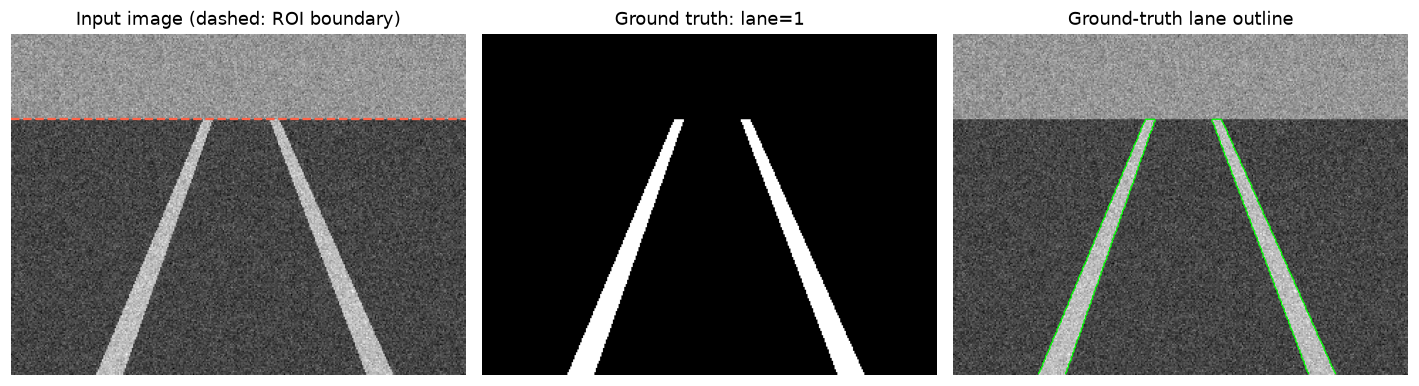

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
axes[0].imshow(train_img, cmap='gray', vmin=0, vmax=255)
axes[0].axhline(59.5, color='tomato', ls='--')
axes[0].set_title('Input image (dashed: ROI boundary)')
axes[1].imshow(train_mask, cmap='gray', vmin=0, vmax=1)
axes[1].set_title('Ground truth: lane=1')
axes[2].imshow(train_img, cmap='gray', vmin=0, vmax=255)
axes[2].contour(train_mask, levels=[0.5], colors=['lime'], linewidths=0.8)
axes[2].set_title('Ground-truth lane outline')
for ax in axes:
    ax.axis('off')
plt.tight_layout()
plt.show()


## 3. 정답과 얼마나 다른가: 손실 함수 정의

이번 손실은 **도로 영역의 픽셀 오답률**입니다. 평가 영역(ROI, Region of Interest)은 행 인덱스 60부터 마지막까지입니다.

$$L(T)=\frac{1}{N}\sum_{(i,j)\in\mathrm{ROI}}\mathbf{1}[\hat y_{ij}(T)\ne y_{ij}]$$

$N=180\times320=57{,}600$은 평가하는 픽셀 수입니다. 대괄호 안의 조건이 참이면 1, 거짓이면 0으로 세어 평균을 냅니다. 손실 0.01은 1%의 픽셀을 틀렸다는 뜻입니다.

`pred != mask`는 불리언 배열을 만듭니다. NumPy의 평균은 `True`를 1, `False`를 0으로 취급하므로 오답률이 됩니다.

**왜 하늘을 제외할까요?** 이 예제의 목표는 도로에서 차선을 찾는 것입니다. 밝은 하늘을 함께 채점하면 하늘을 배경으로 맞히는 문제까지 임계값 선택에 영향을 줍니다. 여기서는 관심 영역을 고정하여 목표를 명확히 합니다. 예측 영상에 하늘이 하얗게 보여도 아래 손실에는 포함되지 않습니다.


In [9]:
def error_rate(img, mask, T):
    pred = (img > T).astype(np.uint8)
    road = slice(60, None)
    return np.mean(pred[road] != mask[road])

print('평가 픽셀 수:', train_mask[60:].size)
print(f'T=127일 때 학습 사진 오답률: {error_rate(train_img, train_mask, 127):.4%}')


평가 픽셀 수: 57600
T=127일 때 학습 사진 오답률: 0.0625%


## 4. 학습: 256개 후보를 모두 시험하기

우리가 풀 문제는 다음과 같습니다.

$$T^*=\underset{T\in\{0,\ldots,255\}}{\arg\min}\ L(T)$$

`min`은 가장 작은 손실 **값**, `argmin`은 그 값이 나타나는 **위치**를 반환합니다. 이 위치를 `Ts`에 넣어 실제 임계값을 얻습니다.

이 방식은 완전 탐색 또는 그리드 탐색입니다. 이번에는 파라미터가 하나이고 후보가 256개라서 가능합니다. 정수 임계값은 8비트 영상에서 가능한 판정 경계를 표현하기에 충분합니다. $T=0$은 밝기가 0인 픽셀을 제외한 모두를 차선으로, $T=255$는 모두를 배경으로 예측합니다.

최솟값을 주는 임계값이 여러 개면 `np.argmin()`은 **첫 번째 위치**를 선택합니다. 후보를 오름차순으로 나열했으므로 가장 작은 임계값이 선택됩니다. 이런 경우 선택된 값만이 유일한 정답은 아닙니다.


In [10]:
Ts = np.arange(256)
errors = np.array([error_rate(train_img, train_mask, T) for T in Ts])
best_T = int(Ts[np.argmin(errors)])
tied_Ts = Ts[errors == errors.min()]

print(f'학습으로 찾은 임계값 T = {best_T}  (학습 사진 오답률 {errors.min():.2%})')
print(f'같은 최소 오답률을 주는 T: {tied_Ts.tolist()}')
print(f'도로 영역 오답 픽셀 수: {np.count_nonzero((train_img[60:] > best_T) != train_mask[60:])}')


학습으로 찾은 임계값 T = 136  (학습 사진 오답률 0.02%)
같은 최소 오답률을 주는 T: [136]
도로 영역 오답 픽셀 수: 13


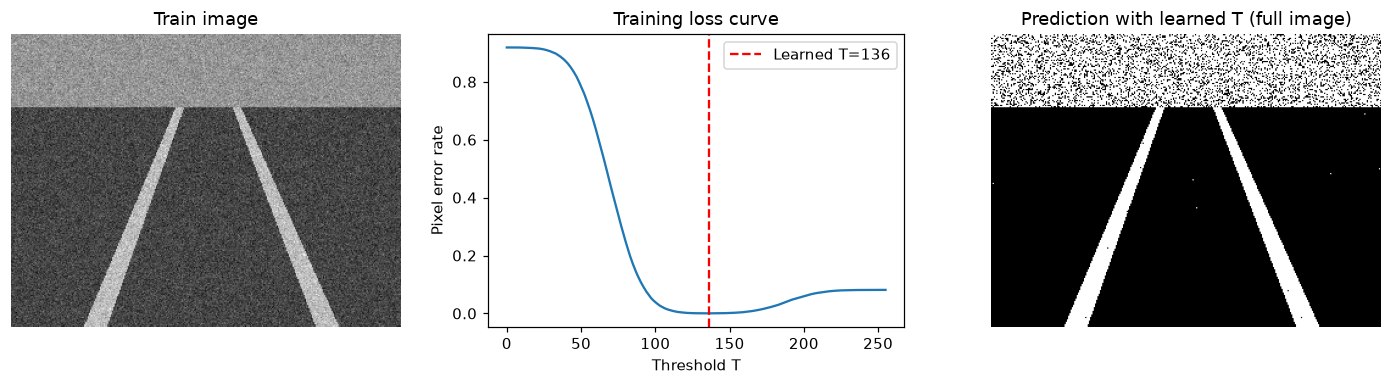

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
axes[0].imshow(train_img, cmap='gray', vmin=0, vmax=255)
axes[0].set_title('Train image')
axes[1].plot(Ts, errors)
axes[1].axvline(best_T, color='r', ls='--', label=f'Learned T={best_T}')
axes[1].set(xlabel='Threshold T', ylabel='Pixel error rate', title='Training loss curve')
axes[1].legend()
axes[2].imshow(train_img > best_T, cmap='gray', vmin=0, vmax=1)
axes[2].set_title('Prediction with learned T (full image)')
for ax in (axes[0], axes[2]):
    ax.axis('off')
plt.tight_layout()
plt.show()


### 손실 곡선 읽는 법

- **T가 너무 작을 때:** 어두운 아스팔트도 차선으로 예측합니다. 배경을 차선으로 잘못 검출하는 오류가 많아집니다.
- **T가 적절할 때:** 아스팔트와 차선을 잘 나누므로 오답률이 작아집니다.
- **T가 너무 클 때:** 차선도 배경으로 예측합니다. 차선을 놓치는 오류가 많아집니다.

가로축은 학습 횟수나 시간이 아니라 **후보 파라미터 T**입니다. 같은 사진에 임계값만 바꿔 평가한 그림입니다. 딥러닝에서 자주 보는 ‘학습 횟수에 따른 손실’ 그래프와 가로축이 다릅니다.

여기서는 `error_rate()`가 손실 함수이고, 이를 여러 T에서 계산하여 그린 것이 손실 곡선입니다. 픽셀 밝기가 정수라서 판정이 바뀌는 지점에서만 값이 변하는 계단형 성질이 있습니다. 원본 사진 크기에서의 픽셀 오답률이 아주 작으면 그래프상 0처럼 보일 수도 있습니다.


## 5. Otsu와 비교: 둘 다 자동이지만 기준은 다르다

Otsu는 정답 마스크를 사용하지 않고, 밝기 히스토그램을 두 집단으로 나누는 기준을 최적화합니다. 구체적으로는 두 집단 사이 분산을 크게 만드는 임계값을 찾습니다. 이에 비해 이번 학습은 **정답과의 불일치**를 직접 최소화합니다.

Otsu도 어떤 기준을 최적화하지만, 이번과 같은 정답 마스크 기반 지도학습은 아닙니다. Otsu가 차선이라는 의미를 알고 있는 것도 아닙니다. 비교 조건을 맞추기 위해 Otsu에도 하늘을 제외한 도로 영상만 전달합니다.

아래 Otsu 값은 **학습 사진에서 한 번** 구한 참고 값입니다. 이후 기본 평가 표의 두 방법은 학습 T와 고정 127입니다. 새 사진마다 Otsu를 다시 계산하는 방식은 입력 사진에 맞춰 임계값을 다시 정하는 별도의 방법이므로 구분해야 합니다.


In [12]:
otsu_T, _ = cv2.threshold(train_img[60:], 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
print(f'Otsu가 고른 값 = {int(otsu_T)} (정답을 보지 않고 히스토그램만 사용)')
print(f'{"방법":<12} {"T":>5} {"학습 사진 오답률":>16}')
for name, T in [('learned', best_T), ('fixed127', 127), ('Otsu(train)', int(otsu_T))]:
    print(f'{name:<12} {T:>5} {error_rate(train_img, train_mask, T):>16.4%}')


Otsu가 고른 값 = 129 (정답을 보지 않고 히스토그램만 사용)
방법               T        학습 사진 오답률
learned        136          0.0226%
fixed127       127          0.0625%
Otsu(train)    129          0.0469%


## 6. 평가: 새 사진에는 T를 그대로 적용

학습은 이미 끝났습니다. 이제 새로운 잡음을 가진 사진 세 장을 만들고, **best_T를 바꾸지 않은 채** 적용합니다. 밝기 1.0 사진도 학습 사진을 재사용한 것이 아니라 새로 생성한 사진입니다.

평가에서는 정답 마스크를 오답률 계산에만 사용합니다. 평가 정답을 보고 T를 다시 고르면 그 사진은 더 이상 독립적인 최종 평가 데이터가 아닙니다.

이 합성 예제에서는 사진마다 잡음은 달라지지만 차선 모양과 배경 구조는 같습니다. 따라서 실제 도로 장면 전체에 대한 일반화를 검증하는 실험은 아닙니다. 우선 조명 변화라는 한 가지 조건을 살펴보는 실습입니다.


In [13]:
test_cases = []
print('새 사진 밝기   학습T 오답률   고정127 오답률')
for b in (1.0, 0.8, 1.2):
    test_img, test_mask = make_road(brightness=b)
    test_cases.append((b, test_img, test_mask))
    print(f'   x{b:<4}      {error_rate(test_img, test_mask, best_T):8.2%}'
          f'      {error_rate(test_img, test_mask, 127):8.2%}')


새 사진 밝기   학습T 오답률   고정127 오답률
   x1.0          0.03%         0.06%
   x0.8          1.67%         0.73%
   x1.2          0.15%         0.68%


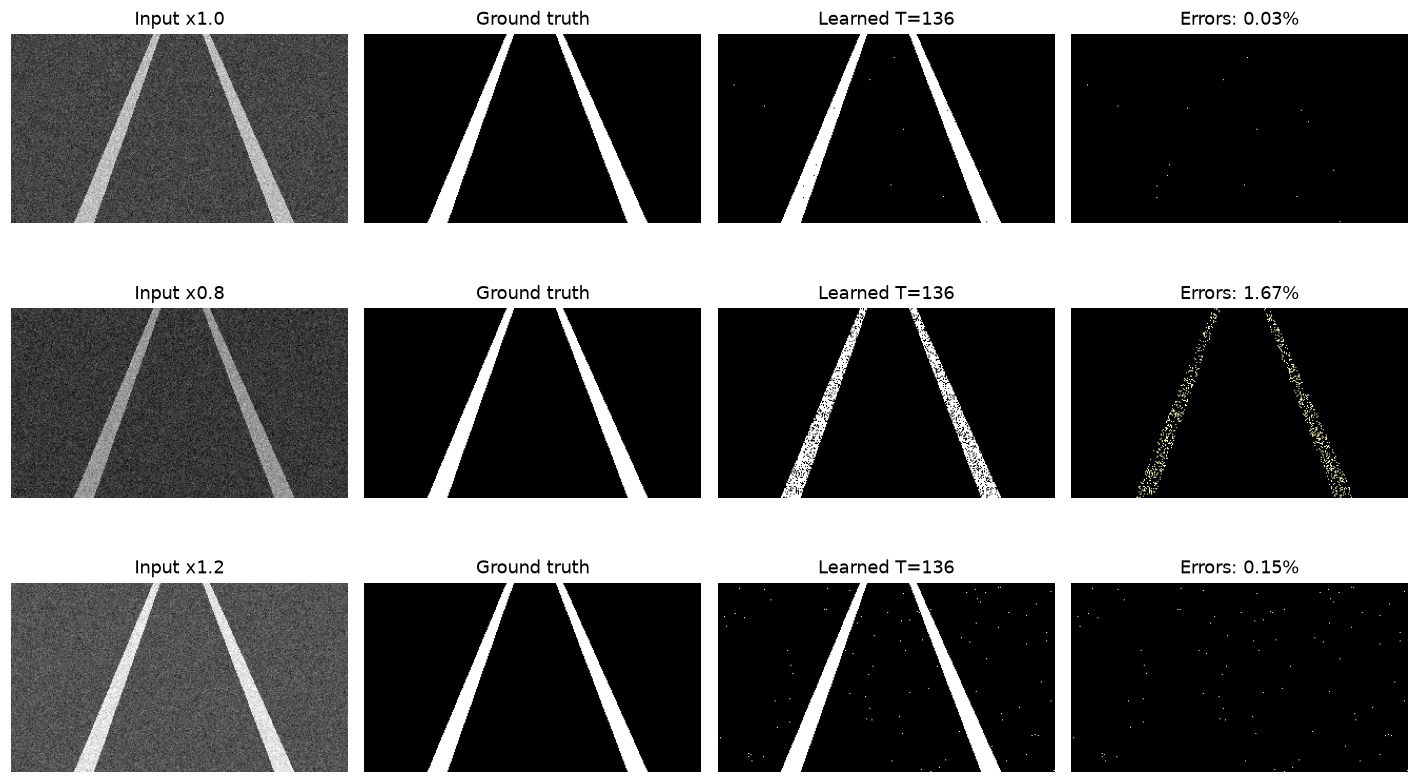

In [14]:
fig, axes = plt.subplots(3, 4, figsize=(13, 8))
for row, (b, img, mask) in enumerate(test_cases):
    roi_img, roi_mask = img[60:], mask[60:]
    learned_pred = roi_img > best_T
    wrong = learned_pred != roi_mask
    panels = [roi_img, roi_mask, learned_pred, wrong]
    titles = [f'Input x{b}', 'Ground truth', f'Learned T={best_T}',
              f'Errors: {wrong.mean():.2%}']
    for col, (panel, title) in enumerate(zip(panels, titles)):
        axes[row, col].imshow(panel, cmap='gray' if col < 3 else 'magma',
                              vmin=0, vmax=255 if col == 0 else 1)
        axes[row, col].set_title(title)
        axes[row, col].axis('off')
plt.tight_layout()
plt.show()


### 밝기가 변하면 왜 성능이 달라질까?

밝기 1.0에서 아스팔트와 차선의 기본 밝기는 각각 70과 190입니다. 밝기 0.8에서는 56과 152, 밝기 1.2에서는 84와 228이 됩니다. 잡음이 더해지기 전의 값이 이처럼 이동합니다.

어두운 사진에서는 차선이 임계값 아래로 내려가 **차선 누락**이 늘 수 있습니다. 밝은 사진에서는 아스팔트가 임계값을 넘어서 **잘못된 차선 검출**이 늘 수 있습니다. 이것은 학습 때 본 밝기 분포와 평가 때의 분포가 달라지는 문제입니다.

학습 T가 항상 127보다 좋은 것은 아닙니다. 학습 사진에서는 후보 127도 검사했으므로 학습 T의 손실이 127보다 클 수 없지만, 새 사진에서는 그런 보장이 없습니다. 표의 차이가 작다면 다음 실험처럼 소수점 자릿수를 늘리고 여러 사진을 함께 평가해야 합니다.


## 7. 주의할 점: 전체 오답률이 낮아도 차선을 놓칠 수 있다

도로에서는 배경 픽셀이 차선보다 훨씬 많습니다. 이처럼 클래스별 데이터 수가 크게 다른 상황을 **클래스 불균형**이라고 합니다. 전부 배경이라고 예측해도 전체 오답률은 차선 비율만큼만 발생합니다.

| 정답 | 예측 | 이름 | 의미 |
|---|---|---|---|
| 차선 1 | 차선 1 | TP | 차선을 제대로 찾음 |
| 배경 0 | 차선 1 | FP | 배경을 차선으로 오인 |
| 차선 1 | 배경 0 | FN | 차선을 놓침 |
| 배경 0 | 배경 0 | TN | 배경을 제대로 제외 |

- 정밀도(precision) = TP / (TP + FP): 차선이라고 예측한 것 중 진짜 차선의 비율
- 재현율(recall) = TP / (TP + FN): 실제 차선 중 찾아낸 비율
- IoU = TP / (TP + FP + FN): 예측 차선과 정답 차선의 교집합 / 합집합

전체 오답률은 작을수록, 위 세 지표는 클수록 좋습니다. 아래 함수는 분모가 0이면 정의할 수 없다는 뜻으로 `nan`을 반환합니다. 보조 지표는 해석용이며, 기본 실습에서 T를 고르는 기준은 여전히 전체 픽셀 오답률입니다.


In [15]:
def lane_metrics(img, mask, T):
    pred = img[60:] > T
    truth = mask[60:].astype(bool)
    tp = np.count_nonzero(pred & truth)
    fp = np.count_nonzero(pred & ~truth)
    fn = np.count_nonzero(~pred & truth)
    tn = np.count_nonzero(~pred & ~truth)
    def ratio(a, b):
        return a / b if b else float('nan')
    return {'error': (fp + fn) / truth.size,
            'precision': ratio(tp, tp + fp), 'recall': ratio(tp, tp + fn),
            'iou': ratio(tp, tp + fp + fn), 'TP': tp, 'FP': fp, 'FN': fn, 'TN': tn}

print(f'도로 영역의 차선 픽셀 비율: {train_mask[60:].mean():.2%}')
print('모두 배경으로 예측하는 T=255:', lane_metrics(train_img, train_mask, 255))
print('\n밝기   오답률      정밀도      재현율      IoU       FP     FN')
for b, img, mask in test_cases:
    m = lane_metrics(img, mask, best_T)
    print(f'{b:3.1f}  {m["error"]:8.4%}  {m["precision"]:9.2%}  '
          f'{m["recall"]:9.2%}  {m["iou"]:9.2%}  {m["FP"]:5d}  {m["FN"]:5d}')


도로 영역의 차선 픽셀 비율: 8.12%
모두 배경으로 예측하는 T=255: {'error': np.float64(0.08125), 'precision': nan, 'recall': np.float64(0.0), 'iou': np.float64(0.0), 'TP': np.int64(0), 'FP': np.int64(0), 'FN': np.int64(4680), 'TN': np.int64(52920)}

밝기   오답률      정밀도      재현율      IoU       FP     FN
1.0   0.0278%     99.83%     99.83%     99.66%      8      8
0.8   1.6736%    100.00%     79.40%     79.40%      0    964
1.2   0.1545%     98.13%    100.00%     98.13%     89      0


## 8. 추가 실험: 여러 밝기를 학습에 포함하기

‘어두운 사진에서 약해지면 어두운 사진도 학습에 넣어 보자’라는 아이디어를 시험합니다. 다음은 0.8·1.0·1.2배 밝기마다 4장씩, 총 12장의 학습 사진에서 평균 오답률이 최소인 임계값 하나를 구합니다.

밝기를 바꾸어 학습 예를 늘리는 아이디어는 **데이터 증강**과 연결됩니다. 여기서는 합성 생성기로 각 밝기의 새 사진을 직접 만듭니다. 실제 증강에서는 사진의 밝기를 바꿔도 차선 위치가 변하지 않으므로 기존 마스크를 함께 사용할 수 있습니다.

중요한 한계도 있습니다. 여러 밝기를 학습해도 T는 여전히 하나입니다. 밝기마다 원하는 경계가 달라지면 모든 사진을 완벽히 맞히는 단일 T가 없을 수 있습니다. 여러 사진의 평균 손실을 줄이는 **절충값**을 찾는 것입니다.

추가 실험은 기본 실습과 별도의 시드 2026에서 시작합니다. 아래 생성기는 원래의 `make_road()`를 그대로 이용하며, 추가 실험이 기본 실습의 난수 상태를 바꾸지 않도록 상태를 복구합니다.


학습 사진 12장, 여러 밝기에서 학습한 T = 129
12장 평균 학습 오답률: 0.4812%


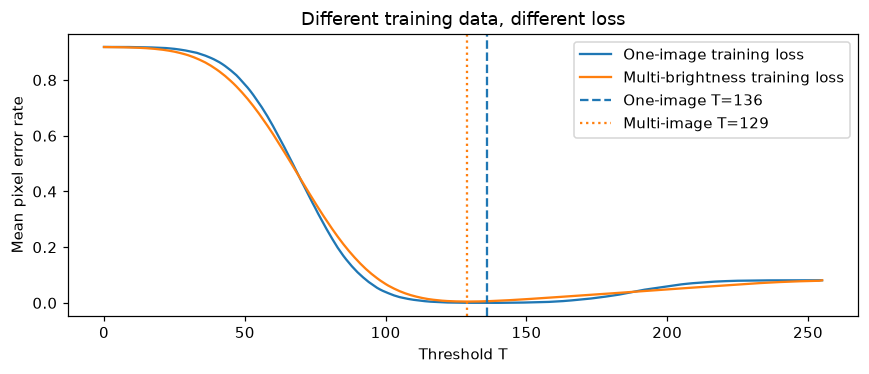

In [16]:
def make_dataset(brightnesses, repeats, seed):
    global rng
    original_rng = rng
    rng = np.random.default_rng(seed)
    try:
        return [(b, *make_road(brightness=b))
                for b in brightnesses for _ in range(repeats)]
    finally:
        rng = original_rng

multi_train = make_dataset((0.8, 1.0, 1.2), repeats=4, seed=2026)
multi_errors = np.array([
    np.mean([error_rate(img, mask, T) for _, img, mask in multi_train])
    for T in Ts
])
multi_T = int(Ts[np.argmin(multi_errors)])
print(f'학습 사진 {len(multi_train)}장, 여러 밝기에서 학습한 T = {multi_T}')
print(f'12장 평균 학습 오답률: {multi_errors.min():.4%}')

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(Ts, errors, label='One-image training loss')
ax.plot(Ts, multi_errors, label='Multi-brightness training loss')
ax.axvline(best_T, color='C0', ls='--', label=f'One-image T={best_T}')
ax.axvline(multi_T, color='C1', ls=':', label=f'Multi-image T={multi_T}')
ax.set(xlabel='Threshold T', ylabel='Mean pixel error rate', title='Different training data, different loss')
ax.legend()
plt.tight_layout()
plt.show()


### 새 평가 세트에서 비교하기

아래는 시드 2027로 만든 **새 사진**입니다. 밝기별 10장씩 평균을 계산해 한 장의 우연한 잡음이 미치는 영향을 줄입니다. 학습 범위에 포함된 0.8·1.0·1.2와, 범위 밖의 0.6·1.4를 함께 관찰합니다.

평가 사진의 정답으로 T를 다시 선택하지 않습니다. 아래 결과를 보고 추가로 모델을 수정한다면, 최종 성능 확인을 위한 별도 평가 세트를 다시 마련해야 합니다. 실제 개발에서는 학습 세트로 파라미터를 학습하고, 검증 세트로 설계와 설정을 선택하고, 최종 평가 세트로 마지막 성능을 확인합니다.

사진마다 평가 픽셀 수가 같아서 여기서는 사진별 오답률의 평균과 전체 픽셀을 합친 오답률이 같습니다. 크기가 다른 영상에서는 두 평균이 달라질 수 있습니다.


밝기   한 장 학습T     고정127       여러 장 학습T (각각 10장 평균)
0.6       7.2931%       6.3262%       6.5818%
0.8       1.6483%       0.7333%       0.8934%
1.0       0.0161%       0.0585%       0.0413%
1.2       0.1503%       0.6552%       0.4747%
1.4       1.3783%       4.4170%       3.4840%


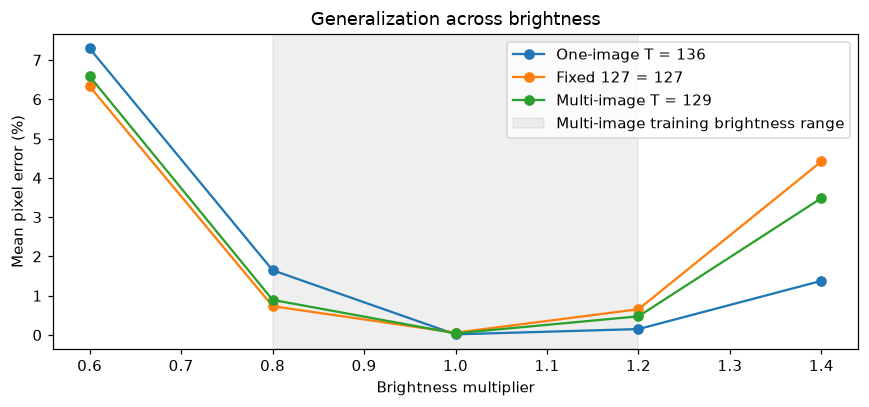

In [17]:
eval_brightnesses = (0.6, 0.8, 1.0, 1.2, 1.4)
extra_test = make_dataset(eval_brightnesses, repeats=10, seed=2027)
methods = {'One-image T': best_T, 'Fixed 127': 127, 'Multi-image T': multi_T}
mean_results = {name: [] for name in methods}

print('밝기   한 장 학습T     고정127       여러 장 학습T (각각 10장 평균)')
for b in eval_brightnesses:
    group = [(img, mask) for bb, img, mask in extra_test if bb == b]
    values = []
    for name, T in methods.items():
        value = np.mean([error_rate(img, mask, T) for img, mask in group])
        mean_results[name].append(value)
        values.append(value)
    print(f'{b:3.1f}    {values[0]:10.4%}    {values[1]:10.4%}    {values[2]:10.4%}')

fig, ax = plt.subplots(figsize=(8, 3.8))
for name, values in mean_results.items():
    ax.plot(eval_brightnesses, np.array(values) * 100, marker='o',
            label=f'{name} = {methods[name]}')
ax.axvspan(0.8, 1.2, color='gray', alpha=0.12, label='Multi-image training brightness range')
ax.set(xlabel='Brightness multiplier', ylabel='Mean pixel error (%)', title='Generalization across brightness')
ax.legend()
plt.tight_layout()
plt.show()


### 추가 실험을 해석할 때

여러 밝기로 학습한 T가 특정 밝기에서 개선되더라도 다른 밝기에서는 나빠질 수 있습니다. 평균 손실 최소화는 모든 조건에서의 성능 향상을 보장하지 않습니다. 학습 범위를 벗어난 밝기에서 성능이 떨어지는지도 함께 보세요.

이 실험에서는 여러 밝기를 넣는 동시에 사진 수도 늘어났습니다. 효과를 엄밀히 분리하고 싶다면 **밝기 1.0의 12장**과 **여러 밝기의 12장**을 같은 조건으로 비교하고, 시드도 여러 개 바꿔 반복해야 합니다. 이것이 비교 실험에서 조건을 통제하는 방법입니다.


## 9. 딥러닝과 연결하기

이번 실습과 딥러닝은 ‘예측 → 정답과 비교 → 손실 계산 → 파라미터 선택 또는 수정’이라는 큰 흐름을 공유합니다.

| 항목 | 이번 실습 | 신경망 학습의 일반적인 예 |
|---|---|---|
| 파라미터 | 임계값 1개 | 많은 가중치와 편향 |
| 예측 | 밝기를 기준으로 0/1 판정 | 입력에서 특징을 계산해 점수·확률 출력 |
| 손실 | 픽셀 오답률 | 교차 엔트로피 등 미분 가능한 손실 |
| 최적화 | 256개 후보 전부 평가 | 경사하강법 계열로 반복 갱신 |
| 최종 확인 | 학습에 쓰지 않은 새 사진 | 학습에 쓰지 않은 평가 데이터 |

파라미터마다 후보가 256개이고 파라미터가 $d$개라면 조합 수는 $256^d$입니다. 2개만 되어도 65,536개이며, 백만 개라면 완전 탐색은 현실적으로 불가능합니다.

그렇다고 이번 `error_rate()`에 경사하강법을 그대로 적용하는 것은 적절하지 않습니다. `img > T`는 딱 끊어지는 판정이고 손실도 계단형이어서, 기울기가 유용한 방향 정보를 주지 못합니다. 신경망에서는 보통 미분 가능한 출력과 손실로 학습하고, 최종 예측 시 이산 판정으로 바꿉니다. 8회차 경사하강법에서 이 차이를 다시 연결해 볼 수 있습니다.


## 10. 직접 해 볼 과제

### A. 기본 확인

1. `example_pixels > 127`을 `>= 127`로 바꾸면 어느 픽셀의 예측이 달라질까요?
2. `errors.min()`과 `Ts[np.argmin(errors)]`가 각각 무엇인지 말해 보세요.
3. 가운데 손실 곡선의 가로축과 세로축을 설명하세요. 학습 시간에 따른 그래프인가요?
4. 새 사진에서 T를 다시 고르면 왜 ‘학습한 T를 그대로 적용한 평가’가 아닐까요?

### B. 실험 후 기록

1. 학습 T, Otsu T, 고정 127의 학습 사진 오답률을 기록하세요.
2. 밝기 0.8 사진에서 FP와 FN 중 어떤 오류가 더 많은지 확인하세요.
3. `noise=18`을 5 또는 35로 바꾸어 실험하세요. 학습과 평가의 잡음 조건을 어떻게 바꿨는지 함께 기록하세요.
4. 학습 세트의 밝기 범위를 넓혀 보고, 새 평가 세트에서 비교하세요.
5. 전체 오답률 대신 `1 - IoU`를 최소화하면 T가 어떻게 바뀔까요? 같은 학습 데이터로 비교하되 평가 데이터로 T를 고르지 마세요.

코드를 수정한 뒤에는 커널을 재시작하고 모두 실행하여 수정 사항이 어느 셀에 영향을 주었는지 확인하세요. 마지막 결과 하나만 비교하기보다 입력 조건·학습 T·평가 지표를 함께 기록하는 것이 좋습니다.

### 실험 기록 양식

| 실험 | 학습 밝기 / 장수 | 잡음 | 선택한 T | 새 사진 밝기 | 오답률 | 재현율 / IoU | 관찰 |
|---|---|---|---|---|---|---|---|
| 기본 | 1.0 / 1장 | 18 | 직접 기록 | 0.8 | 직접 기록 | 직접 기록 | 직접 기록 |
| 변경 | 직접 기록 | 직접 기록 | 직접 기록 | 직접 기록 | 직접 기록 | 직접 기록 | 직접 기록 |


## 11. 확인 문제 해설

**1. 가장 낮은 점을 찾는 것이 학습인가요?**  
이 예제에서는 그렇습니다. 손실 함수가 `error_rate()`이고, 모든 후보를 계산한 뒤 최소 손실을 주는 파라미터를 선택합니다. 함수 자체와 그 함수를 그린 곡선을 구분하세요. 손실의 수치가 최소인 위치가 여러 개일 수도 있습니다.

**2. 밝기 0.8에서 왜 나빠질 수 있나요?**  
차선 밝기도 함께 낮아지기 때문에, 밝은 장면에서 정한 T보다 어두운 차선 픽셀이 늘어납니다. 차선을 배경으로 놓치는 FN이 증가할 수 있습니다. 여러 조명 조건을 학습에 넣거나 밝기 보정·국소 임계값·더 표현력이 큰 모델을 고려할 수 있습니다. 각각은 추가 가정과 검증이 필요한 별도 방법입니다.

**3. 왜 Otsu와 학습 T가 같지 않을 수 있나요?**  
Otsu는 밝기 분포의 분리 정도, 지도학습은 정답 대비 오류를 최적화합니다. 목적이 다르므로 값도 다를 수 있습니다. 어느 쪽이 항상 우수하다고 단정할 수 없습니다.

**4. 차선을 하나도 찾지 않았는데 오답률이 작을 수 있나요?**  
가능합니다. 배경이 대부분이면 배경만 예측해도 많은 픽셀은 맞힙니다. 그래서 차선 재현율과 IoU를 함께 확인합니다. T=255 실험에서 차선 재현율은 0이며, 차선이라고 예측한 픽셀이 없어서 정밀도는 정의되지 않습니다.

**5. 학습 오답률이 0이면 완벽한 모델인가요?**  
학습 사진 한 장을 모두 맞혔다는 뜻일 뿐입니다. 다른 밝기·잡음·재질·날씨·카메라의 사진에 대한 성능을 보장하지 않습니다. 이 합성 예제는 실제 자율주행 차선 검출 성능을 보여 주는 자료가 아닙니다.

**6. 파라미터가 백만 개면 어떻게 하나요?**  
모든 조합을 시험하는 대신 손실을 줄이는 방향으로 반복 갱신하는 최적화가 필요합니다. 딥러닝에서는 미분 가능한 손실과 역전파로 기울기를 구하고 경사하강법 계열을 사용합니다. 이번의 딱 끊어지는 오답률을 그대로 미분하는 것과는 구분해야 합니다.

**핵심 연결:** 학습 데이터와 정답 → 후보 T로 예측 → 손실 계산 → T 선택 → 새 데이터에서 T를 고정해 평가.


In [18]:
# 실행 결과의 기본 일관성을 점검합니다.
assert train_img.shape == train_mask.shape == (240, 320)
assert set(np.unique(train_mask)) <= {0, 1}
assert errors.shape == (256,)
assert np.isfinite(errors).all() and ((0 <= errors) & (errors <= 1)).all()
assert errors[best_T] == errors.min()
assert error_rate(train_img, train_mask, best_T) <= error_rate(train_img, train_mask, 127)
assert len(multi_train) == 12 and len(extra_test) == 50
print('실습 데이터와 학습 결과의 기본 점검을 통과했습니다.')


실습 데이터와 학습 결과의 기본 점검을 통과했습니다.
